# 01 · Conferência do banco e funil de exclusão

**Projeto:** Apex Imóveis — priorização de segmentos residenciais para um piloto de prospecção (dados públicos de ITBI, cidade de São Paulo).

**Pergunta central do contrato:** quais segmentos de apartamentos apresentam atividade transacional recorrente e preços de referência confiáveis, mesmo depois de corrigir inflação e composição?

**Este notebook faz duas coisas:**
1. Confere se o banco tem exatamente o que a ingestão e as views prometeram.
2. Mostra o funil de exclusão: de todas as guias pagas até o recorte da análise.

> **[NOTEBOOK]** porque aqui o objetivo é *olhar* o resultado para pensar. As regras em si já estão no SQL e nos scripts `.py`.

In [ ]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

sys.path.append(str(Path("..") / "src"))
from database import get_engine

engine = get_engine()

def consulta(sql: str) -> pd.DataFrame:
    return pd.read_sql(sql, engine)

def milhar(n) -> str:
    return f"{n:,.0f}".replace(",", ".")

## 1. Conferência: o banco tem o que esperamos?

Os números esperados vêm do que já havia conferido (ingestão, funil e view). **Se algum divergir, pare:** nada do que vem depois é confiável.

In [14]:
esperado = {"dti_pagas": 787_633, "recorte_final": 228_407, "na_janela": 222_295, "sem_deflator": 0}

obtido = consulta("""
    SELECT (SELECT count(*) FROM staging.itbi_dti)                                   AS dti_pagas,
           (SELECT count(*) FROM analytics.vw_apto_recorte)                          AS recorte_final,
           (SELECT count(*) FROM analytics.vw_apto_recorte WHERE na_janela_analise)  AS na_janela,
           (SELECT count(*) FROM analytics.vw_apto_recorte WHERE sem_deflator)       AS sem_deflator
""").iloc[0].to_dict()

divergencias = []
for chave, valor in esperado.items():
    ok = int(obtido[chave]) == valor
    if not ok:
        divergencias.append(chave)
    print(f"{chave:<14} esperado {milhar(valor):>9} | obtido {milhar(obtido[chave]):>9} | {'OK' if ok else 'DIVERGE'}")
assert not divergencias, f"Divergência em {divergencias}: pare e investigue antes de seguir"

mediana = consulta("""
    SELECT percentile_cont(0.5) WITHIN GROUP (ORDER BY preco_m2_nominal) AS mediana_nominal,
           percentile_cont(0.5) WITHIN GROUP (ORDER BY preco_m2_real)    AS mediana_real
    FROM analytics.vw_apto_recorte
    WHERE na_janela_analise
""").iloc[0]
print(f"\nMediana de R$/m² na janela: nominal {milhar(mediana['mediana_nominal'])} | "
      f"real (dez/2025) {milhar(mediana['mediana_real'])}   (esperado: cerca de 4.495 e 4.872)")

dti_pagas      esperado   787.633 | obtido   787.633 | OK
recorte_final  esperado   228.407 | obtido   228.407 | OK
na_janela      esperado   222.295 | obtido   222.295 | OK
sem_deflator   esperado         0 | obtido         0 | OK

Mediana de R$/m² na janela: nominal 4.495 | real (dez/2025) 4.872   (esperado: cerca de 4.495 e 4.872)


## 2. O funil de exclusão

Cada linha é uma regra. `excluidas` são as linhas que saem naquela etapa; `restantes` são as que seguem. A **ordem** das regras muda quanto sai em cada etapa, mas **não muda o recorte final**.

In [8]:
funil = consulta("""
    SELECT etapa, regra, excluidas, restantes, pct_restante
    FROM analytics.vw_funil_exclusao
    ORDER BY etapa
""")

total = int(funil.loc[funil["etapa"] == 0, "restantes"].iloc[0])
final = int(funil.loc[funil["etapa"] == 8, "restantes"].iloc[0])
assert funil["excluidas"].sum() + final == total, "o funil não fecha"
print(f"O funil fecha: {milhar(funil['excluidas'].sum())} excluídas + {milhar(final)} no recorte = {milhar(total)}")

tabela = funil.copy()
tabela["excluidas"] = tabela["excluidas"].map(milhar)
tabela["restantes"] = tabela["restantes"].map(milhar)
tabela["pct_restante"] = tabela["pct_restante"].map(lambda x: f"{x:.1f}%")
tabela

O funil fecha: 559.226 excluídas + 228.407 no recorte = 787.633


,etapa,regra,excluidas,restantes,pct_restante
0,0,Ponto de partida: todas as DTIs pagas,0,787.633,100.0%
1,1,Excluir natureza diferente de compra e venda,81.131,706.502,89.7%
2,2,Excluir uso diferente de apartamento em condom...,462.858,243.644,30.9%
3,3,Excluir proporção transmitida diferente de 100,12.388,231.256,29.4%
4,4,Excluir cadastro que não é ativo predial,327,230.929,29.3%
5,5,Excluir linhas desalinhadas na fonte,0,230.929,29.3%
6,6,Excluir valor declarado até 10 mil reais,2.522,228.407,29.0%
7,7,Excluir área construída ausente ou zero,0,228.407,29.0%
8,8,RECORTE FINAL: apartamentos válidos para a aná...,0,228.407,29.0%


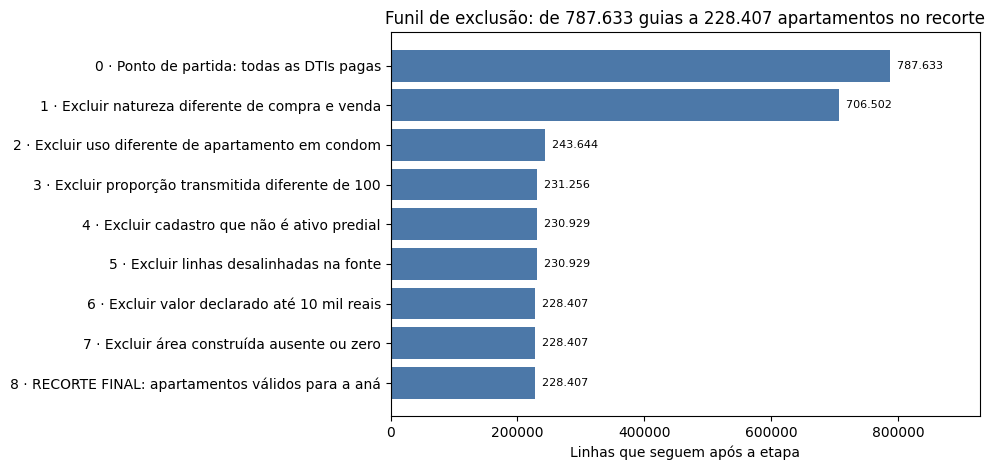

In [11]:
rotulos = funil["etapa"].astype(str) + " · " + funil["regra"].str.slice(0, 46)

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.barh(rotulos, funil["restantes"], color="#4C78A8")
ax.invert_yaxis()
for i, valor in enumerate(funil["restantes"]):
    ax.text(valor, i, f"  {milhar(valor)}", va="center", fontsize=8)
ax.set_xlim(0, funil["restantes"].max() * 1.18)
ax.set_xlabel("Linhas que seguem após a etapa")
ax.set_title(f"Funil de exclusão: de {milhar(total)} guias a {milhar(final)} apartamentos no recorte")
plt.tight_layout()
plt.show()